# Chronoamperometry Simulation with Soft Potato

This notebook shows how to perform a chronoamperometry simulation and compare it with the `cottrell` function from the analytical module (`softpotato.analytical.step`). The goal is to show the full modelling workflow with Soft Potato:

1. **Pre-processing:** Define physical parameters, build the spatial discretization grid, and configure initial and boundary conditions using `DiffusionProblem`.
2. **Solving:** Run the numerical simulation using the explicit finite difference solver (`get_solver("explicit")`).
3. **Post-processing and verification:** Extract concentration profiles, compute Faradaic currents, and benchmark the simulated transient against the theoretical Cottrell response.


## Import libraries


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from softpotato.solver import DiffusionProblem, DirichletBC, get_solver

## Pre-processing


In [2]:
# Parameters
n_electrons = 1

# Initialising the species:
D = 1e-5 # cm2/s
diffusivity = {
    "O": D,
    "R": D
}

# Building the grid:
x_max = 0.1 # cm
x_n = 101 # number of space points
grid = np.linspace(0, x_max, x_n) # 1 mm

# Setting the initial_conditions:
cO_bulk = 0 # mol/cm3
cR_bulk = 1e-6 # mol/cm3
initial_conditions = {
    "O": cO_bulk,
    "R": cR_bulk
}

# Setting the boundary conditions:
cO_left = 1e-6 # mol/cm3
cR_left = 0 # mol/cm3
boundary_conditions = {
    "O": (DirichletBC(cO_left), DirichletBC(cO_bulk)),
    "R": (DirichletBC(cR_left), DirichletBC(cR_bulk)),
}

# Time parameters:
t_max = 10 # s
t_span = (0, t_max)

In [3]:
# Build the problem
problem = DiffusionProblem(
    n_electrons = n_electrons,
    diffusivity = diffusivity,
    grid = grid,
    initial_conditions = initial_conditions,
    boundary_conditions = boundary_conditions
)

## Solving


In [4]:
# Run the simulation:
solver = get_solver("explicit")
result = solver.solve(problem, t_span=t_span)

## Post-processing and verification


In [5]:
# Extract values
c_O = result["O"]
c_R = result["R"]
I = result.currents["O"]
t = result.t
x = result.x

In [6]:
# Use cottrell() from the analytical module to compare with the simulation:
from softpotato.analytical.step import cottrell
area = problem.geometry.area
I_cottrell = cottrell(t=t, n=n_electrons, D=D, c_bulk=cR_bulk, area=area)
i_transient = cottrell(t=t, n=1, D=1e-5, c_bulk=1e-3, area=0.07)

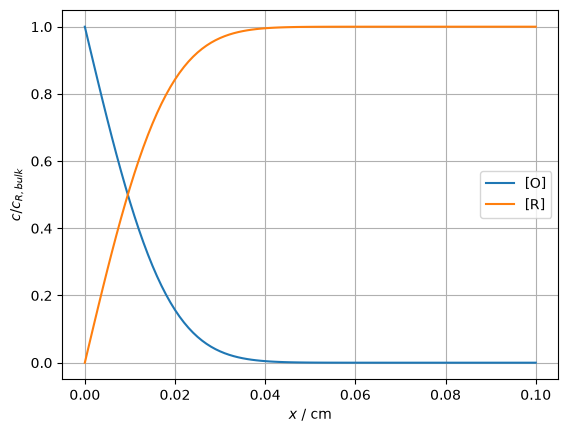

In [7]:
# Plot results
plt.figure()
plt.plot(x, c_O[-1,:]/cR_bulk, label="[O]")
plt.plot(x, c_R[-1,:]/cR_bulk, label="[R]")
plt.xlabel("$x$ / cm")
plt.ylabel(r"$c / c_{R,bulk}$")
plt.grid()
plt.legend()
plt.show()

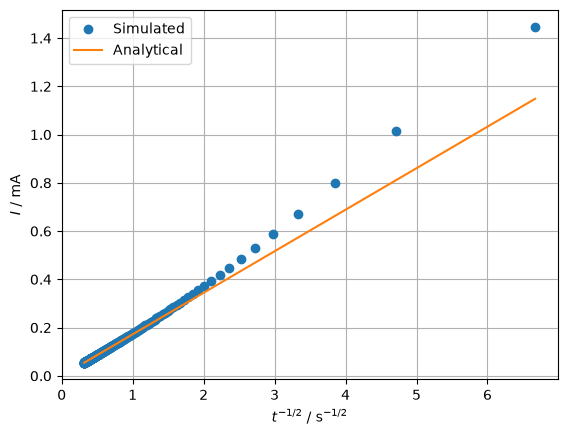

In [8]:
t_sqrt = 1/np.sqrt(t[1:])
plt.figure()
plt.plot(t_sqrt, I[1:]*1e3, "o", label="Simulated")
plt.plot(t_sqrt, I_cottrell[1:]*1e3, "-", label="Analytical")
plt.xlabel("$t^{-1/2}$ / s$^{-1/2}$")
plt.ylabel("$I$ / mA")
plt.legend()
plt.grid()
plt.show()

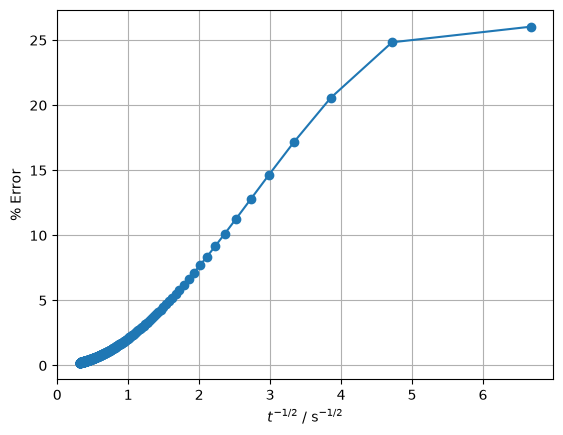

In [9]:
plt.figure()
plt.plot(t_sqrt, 100*np.abs(I[1:] - I_cottrell[1:])/I_cottrell[1:], "o-", label="Error")
plt.xlabel("$t^{-1/2}$ / s$^{-1/2}$")
plt.ylabel("% Error")
plt.grid()
plt.show()